<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/reservoir_1d_physics_exercises_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1D bug reservoir computer exercises lab.

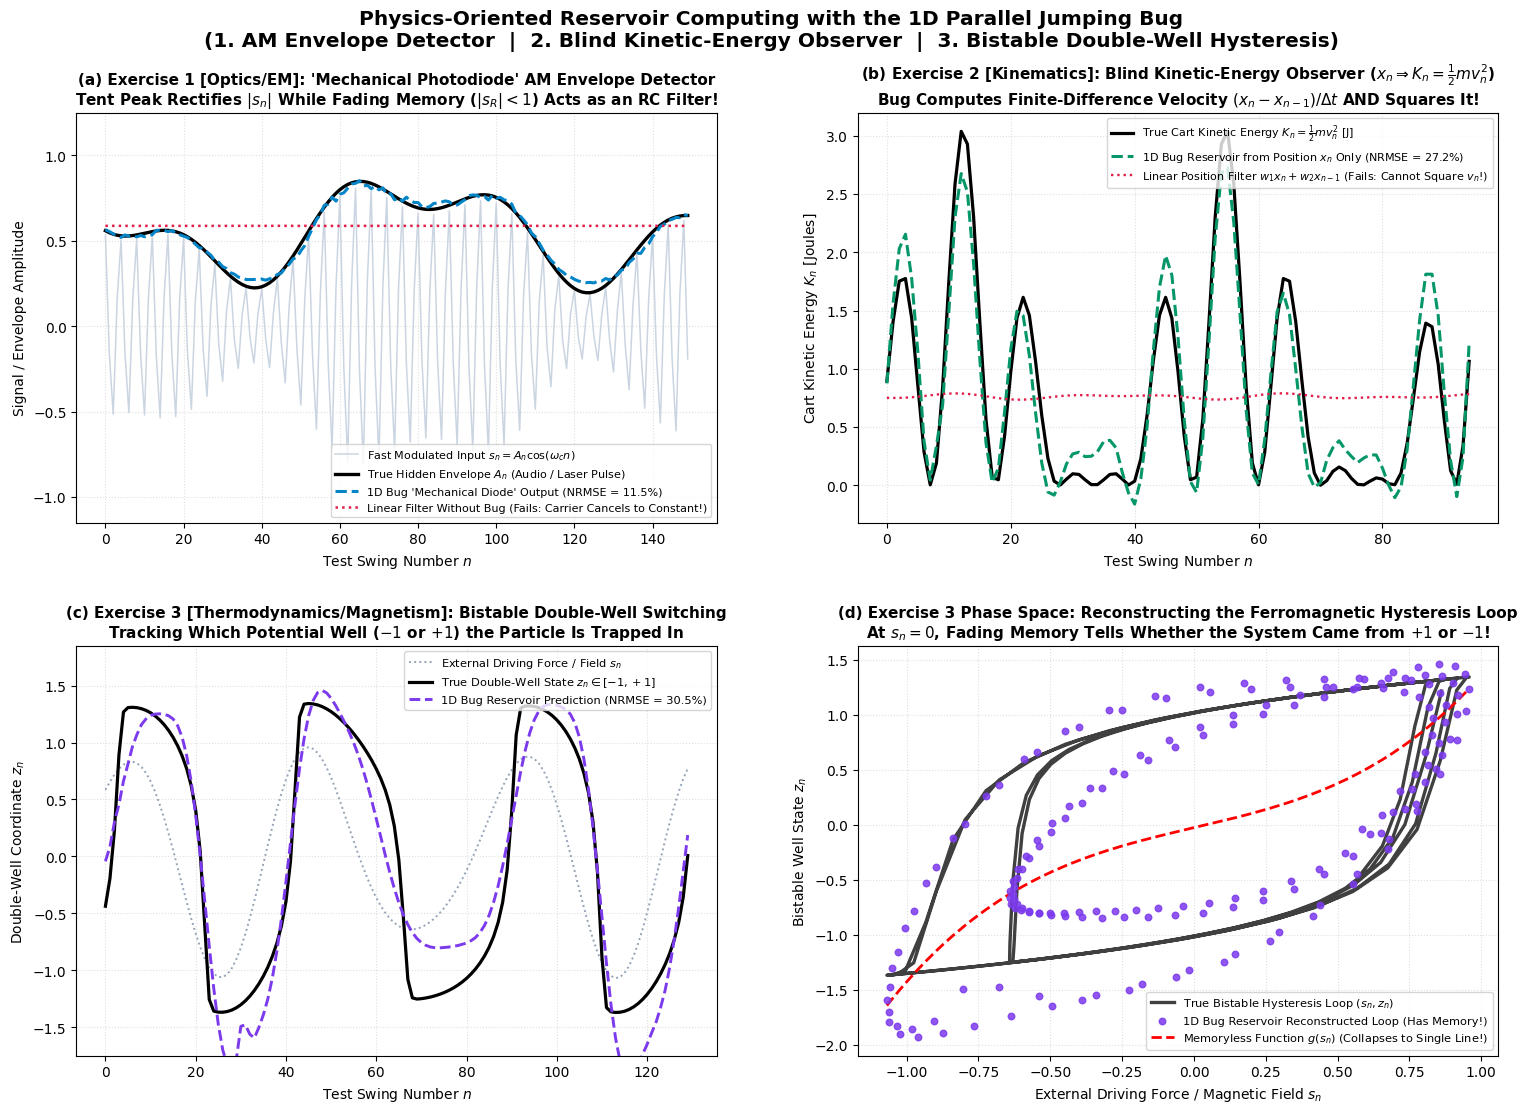

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# =============================================================================
# 1. THE 1D PARALLEL JUMPING BUG RESERVOIR (PURE ALGEBRA — ZERO ODE SOLVER!)
# =============================================================================
def run_1d_bug_physics_reservoir(s_input, n_bugs=12, alpha_scale=0.11):
    """
    Runs a team of `n_bugs` 1D State-Triggered Jumping Bug Pendulums
    tuned across Region I up to the 'Edge of Chaos' (mu in [0.06, 0.142],
    where mu_crit = 0.143 for u_c0 = 0.35).

    Because different bugs have different memory decay rates |s_R| in [0.68, 0.99]
    and different threshold offsets, the team acts as a multi-timescale mechanical
    filter bank + full-wave rectifier!
    """
    N = len(s_input)

    # Spread bug mass ratios from fast memory (0.06) to long Edge-of-Chaos memory (0.142)
    mu_team = np.linspace(0.06, 0.142, n_bugs)
    uc0_team = np.linspace(0.31, 0.36, n_bugs)
    L1_team = (1.0 + 3.0 * mu_team) * (1.0 + 2.0 * mu_team)

    # Alternate input signs (+alpha, -alpha) and magnitudes so bugs probe different parts of the V-fold
    signs = np.where(np.arange(n_bugs) % 2 == 0, 1.0, -1.0)
    scales = np.linspace(0.65, 1.15, n_bugs)
    alpha_team = alpha_scale * signs * scales

    u = np.full(n_bugs, 0.28)

    # Record 5 physical observables per bug + current input s_n + constant bias 1.0
    n_obs = 5
    R_matrix = np.zeros((N, n_obs * n_bugs + 2))

    for n in range(N):
        s_n = float(np.clip(s_input[n], -1.2, 1.2))
        uc_n = np.clip(uc0_team + alpha_team * s_n, 0.06, 0.88)

        # Exact distance from the tent peak BEFORE the jump (proportional to finite-diff velocity!)
        dist_from_peak = np.abs(u - uc_n)

        # 1-Line Algebraic Continuous Tent Map Update (Mechanism II)
        u_peak = L1_team * uc_n
        u = np.where(
            u <= uc_n,
            L1_team * u,                                  # Sub-Threshold: Bug Pumps!
            u_peak * (1.0 - u) / (1.0 - uc_n)             # Super-Threshold: Bug Folds!
        )
        u = np.clip(u, 1e-6, 1.0 - 1e-6)

        # Physical observables of the swinging rod on swing n:
        speed = np.sqrt(u)                                # Bottom angular speed (~ sqrt(u))
        angle = 2.0 * np.arcsin(speed)                    # Turning-point angle theta_max
        tip_x = 2.0 * np.sqrt(u * (1.0 - u))              # Horizontal tip reach sin(theta_max)

        R_matrix[n, :-2] = np.column_stack([u, speed, angle, tip_x, dist_from_peak]).ravel()
        R_matrix[n, -2] = s_n
        R_matrix[n, -1] = 1.0

    return R_matrix


def train_readout(R_train, y_train, ridge=1e-5):
    """Standard Linear Least-Squares / Ridge Regression."""
    n_f = R_train.shape[1]
    return np.linalg.solve(R_train.T @ R_train + ridge * np.eye(n_f), R_train.T @ y_train)


def calc_nrmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2)) / max(np.std(y_true), 1e-12) * 100.0


# =============================================================================
# 2. RUN THE 3 PHYSICS EXPERIMENTS
# =============================================================================
N_tot = 1200
wash = 80
tr_end = 800
steps = np.arange(N_tot)

# -----------------------------------------------------------------------------
# EXERCISE 1: AM Radio / Optical Envelope Detector (Rectifier + RC Low-Pass)
# -----------------------------------------------------------------------------
# Slow physical envelope A_n (e.g., audio wave or laser pulse envelope) > 0
envelope_true = (
    0.58
    + 0.25 * np.sin(2.0 * np.pi * steps / 95.0)
    + 0.14 * np.cos(2.0 * np.pi * steps / 41.0)
)
# High-frequency carrier cos(omega_c * n) with period = 4 swings (omega_c = pi/2)
carrier_wave = np.cos(0.5 * np.pi * steps + 0.3)
s_am = envelope_true * carrier_wave

R_am = run_1d_bug_physics_reservoir(s_am, n_bugs=12, alpha_scale=0.11)
W_am = train_readout(R_am[wash:tr_end], envelope_true[wash:tr_end])
env_pred_bug = R_am[tr_end:] @ W_am
nrmse_am = calc_nrmse(envelope_true[tr_end:], env_pred_bug)

# Compare against a pure Linear Filter (4-tap moving average without the nonlinear bug!)
R_lin_am = np.column_stack([np.roll(s_am, d) for d in range(5)] + [np.ones(N_tot)])
W_lin_am = train_readout(R_lin_am[wash:tr_end], envelope_true[wash:tr_end])
env_pred_lin = R_lin_am[tr_end:] @ W_lin_am

# -----------------------------------------------------------------------------
# EXERCISE 2: Blind Speedometer & Kinetic Energy Observer (x_n -> K_n = 1/2 m v_n^2)
# -----------------------------------------------------------------------------
m_cart = 2.0   # Cart mass (kg)
dt_step = 0.15 # Sampling interval (s)

# Position x_n of a cart oscillating with variable amplitude & frequency (beats)
x_cart = (
    0.55 * np.sin(2.0 * np.pi * steps / 28.0)
    + 0.38 * np.cos(2.0 * np.pi * steps / 17.0)
)
# True velocity v_n = (x_n - x_{n-1}) / dt and Kinetic Energy K_n = 0.5 * m * v_n^2
v_cart = np.zeros(N_tot)
v_cart[1:] = (x_cart[1:] - x_cart[:-1]) / dt_step
K_cart_true = 0.5 * m_cart * (v_cart ** 2)

# Feed ONLY position x_cart into the 1D jumping bug!
R_kin = run_1d_bug_physics_reservoir(x_cart, n_bugs=12, alpha_scale=0.11)
W_kin = train_readout(R_kin[wash:tr_end], K_cart_true[wash:tr_end])
K_pred_bug = R_kin[tr_end:] @ W_kin
nrmse_kin = calc_nrmse(K_cart_true[tr_end:], K_pred_bug)

# Compare against a Linear Position Filter (has memory of x_n, x_{n-1}, x_{n-2}, but no squaring!)
R_lin_kin = np.column_stack([x_cart, np.roll(x_cart, 1), np.roll(x_cart, 2), np.ones(N_tot)])
W_lin_kin = train_readout(R_lin_kin[wash:tr_end], K_cart_true[wash:tr_end])
K_pred_lin = R_lin_kin[tr_end:] @ W_lin_kin

# -----------------------------------------------------------------------------
# EXERCISE 3: Bistable Double-Well / Schmitt-Trigger Hysteresis Loop
# -----------------------------------------------------------------------------
# Smoothly varying external magnetic field / force s_n that sweeps across coercive thresholds +-0.52
s_field = 0.85 * np.sin(2.0 * np.pi * steps / 44.0) + 0.22 * np.cos(2.0 * np.pi * steps / 29.0)

# Overdamped bistable double-well particle: U(z) = -0.5*a*z^2 + 0.25*b*z^4 - s_n*z
z_well = np.zeros(N_tot)
z_cur = -1.0
dt_well = 0.35
for n in range(N_tot):
    # dz/dt = -dU/dz = 1.6 * z - 1.6 * z^3 + 1.8 * s_field[n]
    for _ in range(4):
        z_cur = z_cur + 0.25 * dt_well * (1.6 * z_cur - 1.6 * (z_cur ** 3) + 1.8 * s_field[n])
    z_well[n] = z_cur

R_hyst = run_1d_bug_physics_reservoir(s_field, n_bugs=12, alpha_scale=0.10)
W_hyst = train_readout(R_hyst[wash:tr_end], z_well[wash:tr_end], ridge=1e-4)
z_pred_bug = R_hyst[tr_end:] @ W_hyst
nrmse_hyst = calc_nrmse(z_well[tr_end:], z_pred_bug)

# Compare against an Instantaneous Polynomial Function of s_n alone (Zero Memory!)
R_no_mem = np.column_stack([s_field, s_field**2, s_field**3, np.ones(N_tot)])
W_no_mem = train_readout(R_no_mem[wash:tr_end], z_well[wash:tr_end])
z_pred_nomem = R_no_mem[tr_end:] @ W_no_mem


# =============================================================================
# 3. PLOT THE 4-PANEL PHYSICS RESERVOIR COMPUTING DASHBOARD
# =============================================================================
fig, axs = plt.subplots(2, 2, figsize=(15.8, 11.5))
fig.suptitle(
    "Physics-Oriented Reservoir Computing with the 1D Parallel Jumping Bug\n"
    "(1. AM Envelope Detector  |  2. Blind Kinetic-Energy Observer  |  3. Bistable Double-Well Hysteresis)",
    fontsize=14.5, fontweight="bold", y=0.98
)

# --- Panel (a): Exercise 1 — Mechanical Diode AM Envelope Detector ---
ax_a = axs[0, 0]
n_show1 = 150
t1 = np.arange(n_show1)
ax_a.plot(t1, s_am[tr_end : tr_end + n_show1], color="#cbd5e1", lw=1.1,
          label="Fast Modulated Input $s_n = A_n \\cos(\\omega_c n)$")
ax_a.plot(t1, envelope_true[tr_end : tr_end + n_show1], "k-", lw=2.4,
          label="True Hidden Envelope $A_n$ (Audio / Laser Pulse)")
ax_a.plot(t1, env_pred_bug[:n_show1], "--", color="#0284c7", lw=2.2,
          label=f"1D Bug 'Mechanical Diode' Output (NRMSE = {nrmse_am:.1f}%)")
ax_a.plot(t1, env_pred_lin[:n_show1], ":", color="#e11d48", lw=1.8,
          label="Linear Filter Without Bug (Fails: Carrier Cancels to Constant!)")

ax_a.set_title(
    "(a) Exercise 1 [Optics/EM]: 'Mechanical Photodiode' AM Envelope Detector\n"
    "Tent Peak Rectifies $|s_n|$ While Fading Memory ($|s_R|<1$) Acts as an RC Filter!",
    fontsize=11.0, fontweight="bold"
)
ax_a.set_xlabel("Test Swing Number $n$", fontsize=10)
ax_a.set_ylabel("Signal / Envelope Amplitude", fontsize=10)
ax_a.set_ylim(-1.15, 1.25)
ax_a.grid(True, ls=":", alpha=0.4)
ax_a.legend(loc="lower right", fontsize=8.0)

# --- Panel (b): Exercise 2 — Blind Kinetic-Energy Observer ---
ax_b = axs[0, 1]
n_show2 = 95
t2 = np.arange(n_show2)
ax_b.plot(t2, K_cart_true[tr_end : tr_end + n_show2], "k-", lw=2.3,
          label="True Cart Kinetic Energy $K_n = \\frac{1}{2}m v_n^2$ [J]")
ax_b.plot(t2, K_pred_bug[:n_show2], "--", color="#059669", lw=2.2,
          label=f"1D Bug Reservoir from Position $x_n$ Only (NRMSE = {nrmse_kin:.1f}%)")
ax_b.plot(t2, K_pred_lin[:n_show2], ":", color="#e11d48", lw=1.7,
          label="Linear Position Filter $w_1 x_n + w_2 x_{n-1}$ (Fails: Cannot Square $v_n$!)")

ax_b.set_title(
    "(b) Exercise 2 [Kinematics]: Blind Kinetic-Energy Observer ($x_n \\Rightarrow K_n = \\frac{1}{2}m v_n^2$)\n"
    "Bug Computes Finite-Difference Velocity $(x_n - x_{n-1})/\\Delta t$ AND Squares It!",
    fontsize=11.0, fontweight="bold"
)
ax_b.set_xlabel("Test Swing Number $n$", fontsize=10)
ax_b.set_ylabel("Cart Kinetic Energy $K_n$ [Joules]", fontsize=10)
ax_b.grid(True, ls=":", alpha=0.4)
ax_b.legend(loc="upper right", fontsize=8.0)

# --- Panel (c): Exercise 3 — Bistable Double-Well State z_n(t) ---
ax_c = axs[1, 0]
n_show3 = 130
t3 = np.arange(n_show3)
ax_c.plot(t3, s_field[tr_end : tr_end + n_show3], color="#94a3b8", ls=":", lw=1.4,
          label="External Driving Force / Field $s_n$")
ax_c.plot(t3, z_well[tr_end : tr_end + n_show3], "k-", lw=2.3,
          label="True Double-Well State $z_n \\in [-1, +1]$")
ax_c.plot(t3, z_pred_bug[:n_show3], "--", color="#7c3aed", lw=2.1,
          label=f"1D Bug Reservoir Prediction (NRMSE = {nrmse_hyst:.1f}%)")

ax_c.set_title(
    "(c) Exercise 3 [Thermodynamics/Magnetism]: Bistable Double-Well Switching\n"
    "Tracking Which Potential Well ($-1$ or $+1$) the Particle Is Trapped In",
    fontsize=11.0, fontweight="bold"
)
ax_c.set_xlabel("Test Swing Number $n$", fontsize=10)
ax_c.set_ylabel("Double-Well Coordinate $z_n$", fontsize=10)
ax_c.set_ylim(-1.75, 1.85)
ax_c.grid(True, ls=":", alpha=0.4)
ax_c.legend(loc="upper right", fontsize=8.2)

# --- Panel (d): Exercise 3 — The Phase-Space Hysteresis Loop (z_n vs. s_n) ---
ax_d = axs[1, 1]
s_test = s_field[tr_end : tr_end + 180]
z_test = z_well[tr_end : tr_end + 180]
ax_d.plot(s_test, z_test, "k-", lw=2.4, alpha=0.75, label="True Bistable Hysteresis Loop $(s_n, z_n)$")
ax_d.scatter(s_test, z_pred_bug[:180], color="#7c3aed", s=22, alpha=0.85, zorder=5,
             label="1D Bug Reservoir Reconstructed Loop (Has Memory!)")
ax_d.plot(np.sort(s_test), z_pred_nomem[:180][np.argsort(s_test)], "r--", lw=2.0,
          label="Memoryless Function $g(s_n)$ (Collapses to Single Line!)")

ax_d.set_title(
    "(d) Exercise 3 Phase Space: Reconstructing the Ferromagnetic Hysteresis Loop\n"
    "At $s_n = 0$, Fading Memory Tells Whether the System Came from $+1$ or $-1$!",
    fontsize=11.0, fontweight="bold"
)
ax_d.set_xlabel("External Driving Force / Magnetic Field $s_n$", fontsize=10)
ax_d.set_ylabel("Bistable Well State $z_n$", fontsize=10)
ax_d.grid(True, ls=":", alpha=0.4)
ax_d.legend(loc="lower right", fontsize=8.2)

plt.subplots_adjust(left=0.06, right=0.96, bottom=0.07, top=0.89, wspace=0.22, hspace=0.30)
plt.show()